Molecular-Property-Prediction

In [ ]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, rdFingerprintGenerator
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
import numpy as np
from collections import defaultdict
from rdkit.Chem.Scaffolds import MurckoScaffold
import shap


In [2]:
url = "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv"
df = pd.read_csv(url)

In [3]:
df.head()

,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [4]:
# Convert SMILES to RDKit Fingerprints
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def smiles_to_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        fp = morgan_gen.GetFingerprint(mol)
        return list(fp)
    return None

df['fp'] = df['smiles'].apply(smiles_to_fingerprint)

In [5]:
# Check for any invalid molecules
df['fp'].isna().sum()

0

In [6]:
# Select explicit physicochemical properties from the ESOL dataset
descriptor_cols = [
    'Molecular Weight', 
    'Number of H-Bond Donors', 
    'Number of Rings', 
    'Number of Rotatable Bonds', 
    'Polar Surface Area',
    'Minimum Degree'
]

# Combine fingerprint bit arrays and numerical descriptors into a single matrix X
fp_matrix = np.vstack(df['fp'].values)
desc_matrix = df[descriptor_cols].values
X_combined = np.hstack((fp_matrix, desc_matrix))
y = df['measured log solubility in mols per litre'].values

In [7]:
def generate_scaffold(smiles, include_chirality=False):
    """Compute Murcko scaffold for a SMILES string."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        return MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=include_chirality)
    return None

scaffold_to_indices = defaultdict(list)
for idx, smiles in enumerate(df['smiles']):
    scaffold = generate_scaffold(smiles)
    if scaffold is not None:
        scaffold_to_indices[scaffold].append(idx)
    else:
        # Fallback if scaffold generation fails
        scaffold_to_indices["none"].append(idx)

sorted_scaffolds = sorted(scaffold_to_indices.keys(), key=lambda x: len(scaffold_to_indices[x]), reverse=True)

In [8]:
train_indices = []
test_indices = []
target_test_count = int(len(df) * 0.2)

for scaffold in sorted_scaffolds:
    indices = scaffold_to_indices[scaffold]
    if len(test_indices) < target_test_count:
        test_indices.extend(indices)
    else:
        train_indices.extend(indices)

In [9]:
X_train, X_test = X_combined[train_indices], X_combined[test_indices]
y_train, y_test = y[train_indices], y[test_indices]

print(f"Train set size: {len(X_train)} | Test set size: {len(X_test)}")

Train set size: 811 | Test set size: 317


In [10]:
X_train_scaffold = X_combined[train_indices]
y_train_scaffold = y[train_indices]

X_test_scaffold = X_combined[test_indices]
y_test_scaffold = y[test_indices]

In [11]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, 25],
    'min_samples_split': [5, 10, 15],
    'min_samples_leaf': [2, 4, 6],
    'max_features': ['sqrt', 'log2', 1.0]
}

base_rf = RandomForestRegressor(random_state=42)

random_search = RandomizedSearchCV(
    estimator=base_rf,
    param_distributions=param_dist,
    n_iter=15,
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

In [12]:
random_search.fit(X_train, y_train)
best_model = random_search.best_estimator_
print(f"Best Hyperparameters: {random_search.best_params_}")

Best Hyperparameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 15}


In [13]:
train_preds = best_model.predict(X_train)
test_preds = best_model.predict(X_test)

print("\n--- Final Scaffold-Split Performance ---")
print(f"Train R2: {r2_score(y_train, train_preds):.2f} | Test R2: {r2_score(y_test, test_preds):.2f}")
print(f"Train RMSE: {root_mean_squared_error(y_train, train_preds):.2f} | Test RMSE: {root_mean_squared_error(y_test, test_preds):.2f}")


--- Final Scaffold-Split Performance ---
Train R2: 0.97 | Test R2: 0.40
Train RMSE: 0.37 | Test RMSE: 1.42


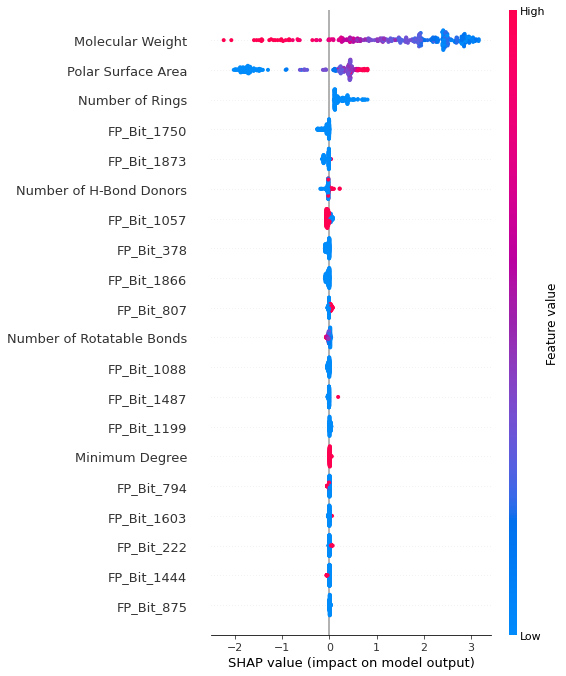

In [16]:
# Create a SHAP explainer for the tree-based model
explainer = shap.TreeExplainer(best_model)

# Calculate SHAP values for the test set (using a subset if dataset is large, but ESOL is small)
shap_values = explainer(X_test)

# 1. Summary Plot: shows global feature importance and impact direction
# (Note: Feature indices 2048 onwards correspond to your explicit descriptors)
feature_names = [f"FP_Bit_{i}" for i in range(2048)] + descriptor_cols
shap_values.feature_names = feature_names

shap.summary_plot(shap_values, X_test, feature_names=feature_names)